# CM laser calibration v2: alignment → space charge → static (v5 scan, 2026-10-22)
K0s runs take ~10 h, so the calibration has to be right on the laser first. Order:
1. **Alignment** of the CM truth to the pad plane (field off: no E×B), checked against the K0s balance of three corrections.
2. **Space charge** from the GEM-current differences between beam blocks of one fill (truth, static and alignment cancel).
3. **Static** at 795xx against the fully aligned truth, with the space charge fixed; target = the K0s-calibrated R².
4. **Second iteration** (field cage + module frames) and the v5 scan that pins down the space-charge profile and the static.
5. **Summary.**

What a TPC-only track keeps of RΔφ(R) = a + bR + cR² + … over 30–76 cm: the R² sagitta (momentum, charge-odd), the
shape beyond the quadratic (resolution), and its pointing (quadratic extrapolated to R = 0). Offset and slope (shift,
rotation) are absorbed. Sector edges (±6°) are excluded everywhere; φ averages are weighted with the K0s-daughter φ distribution.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '/home/yoren/bnl/ROOT/install/lib')
import numpy as np, matplotlib.pyplot as plt
import cmplots as c, truthalign as ta, alignqa as aq, scdiff as sd, scdI_bigscan as sb, calib as cb, v5ana as v, slidestyle
plt.rcParams['figure.dpi'] = 80
plt.rcParams.update({'font.size': 14, 'axes.titlesize': 15, 'axes.labelsize': 15, 'legend.fontsize': 11,
                     'xtick.labelsize': 13, 'ytick.labelsize': 13, 'figure.titlesize': 16})
def show(*figs):
    for f in figs:
        display(slidestyle.restyle(f))
    plt.close('all')
ta.correct_truth()

{0: array([-2.02877286, -0.60458442,  0.35802086]),
 1: array([-2.9392519 , -0.34088598,  0.06488564])}

## 1. Alignment: CM truth → pad plane
### 1a. Field off: the R shape a rigid alignment leaves
Rigid CM alignment from field off (S −2.03 mrad, (−0.61, +0.36) mm; N −2.94 mrad, (−0.34, +0.07) mm) plus 36 pad-module
offsets with their ring means removed. Without B there is no E×B: what remains is geometry.

Welcome to JupyROOT 6.30/06


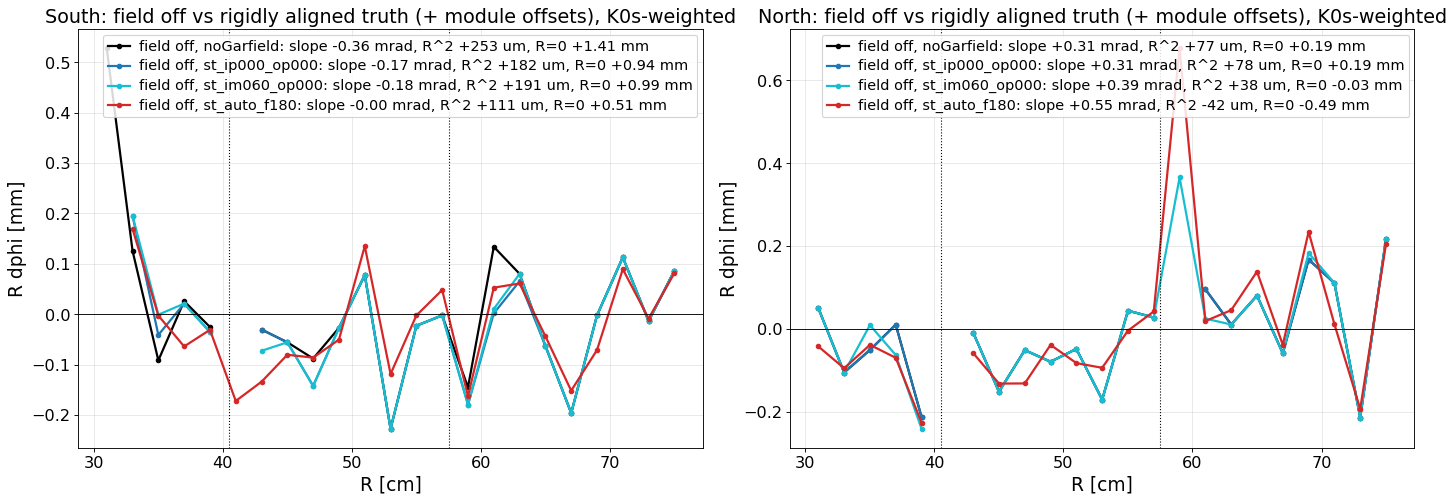

In [2]:
show(aq.fig_zf_alignment())

South +110 … +250 µm, North −40 … +80 µm of R² (range = the field-off correction used). The **full alignment** used from
here on subtracts, from raw field off (no PHGarfield correction: without B nothing moves in RΔφ), the 72 module
offsets and one common fine R profile (2 cm bins, φ-averaged) – it closes exactly in the φ average.

### 1a'. What the alignment is, step by step, and its values
1. **Rigid** CM → pad fit per side on field off, RΔφ only, sector edges excluded: rotation, dx, dy.
2. **72 pad modules** (12 sectors × R1/R2/R3 × 2 sides): median RΔφ per module after the rigid fit, ring mean removed.
3. **Common fine R profile**: median field-off RΔφ per 2 cm in R after steps 1–2 (φ-averaged): the stripe-row
   pattern (±0.2 mm) and the sharp inner-R1 rise in South (+0.6 mm at 31 cm). A coarser sector × 4 cm map (shown for
   its structure) averages that rise away and does not close (R² +157 / +85 µm left).

rigid CM -> pad alignment (field off 78242):
   South: rotation -2.03 mrad, dx -0.60 mm, dy +0.36 mm
   North: rotation -2.94 mrad, dx -0.34 mm, dy +0.06 mm


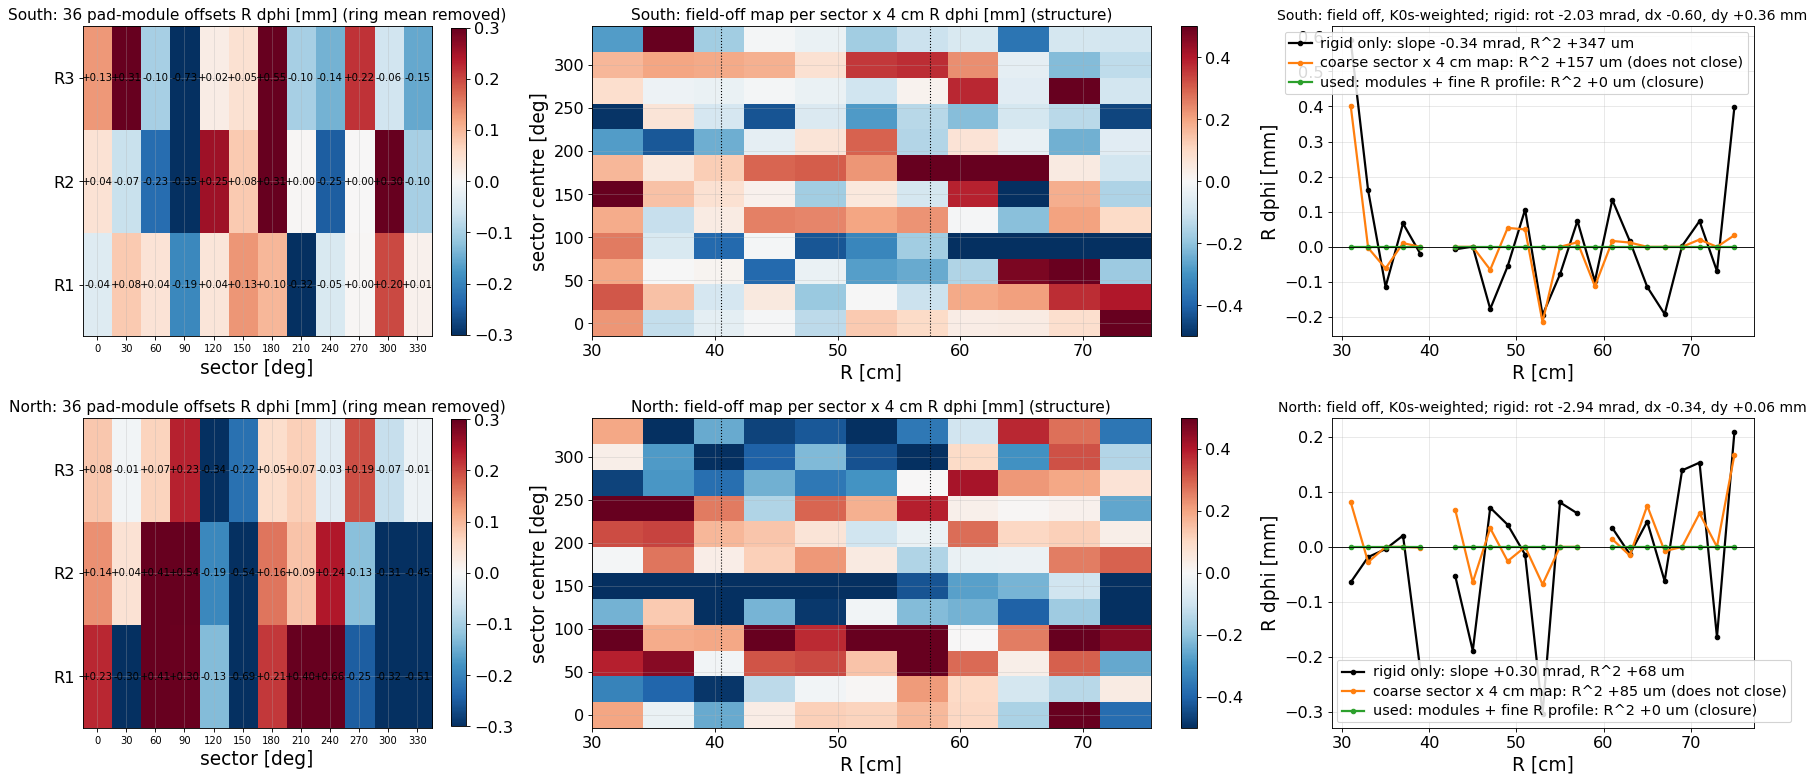

In [3]:
print('rigid CM -> pad alignment (field off 78242):')
for s, (rot, dx, dy) in cb.alignment_values().items():
    print(f"   {c.SIDES[s]:5s}: rotation {rot:+.2f} mrad, dx {dx:+.2f} mm, dy {dy:+.2f} mm")
show(cb.fig_alignment())

**Applying it at the pad plane.** Field off measures the CM pattern relative to the pads; it cannot tell which one moved.
If the CM stripes are where the drawing puts them, the 72 module offsets (up to ±0.3 mm) are pad-module positions and
can be applied to the clusters in local coordinates like a module alignment; the within-module stripe-row pattern
(±0.2 mm, period ~4 cm) looks like CM / pad-row geometry and should stay with the truth.

### 1b. Check against the tracks: K0s balance vs laser R² (795xx)
K0s: (⟨1/pT⁻⟩ − ⟨1/pT⁺⟩)/2 × 11.1 mm, cut03, mass 0.48–0.515 for every correction.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/alignqa.py:486: RuntimeWarning: Mean of empty slice
  return dec(np.nanmean([wprof(x) for x in xs], axis=0), ta.PRC)


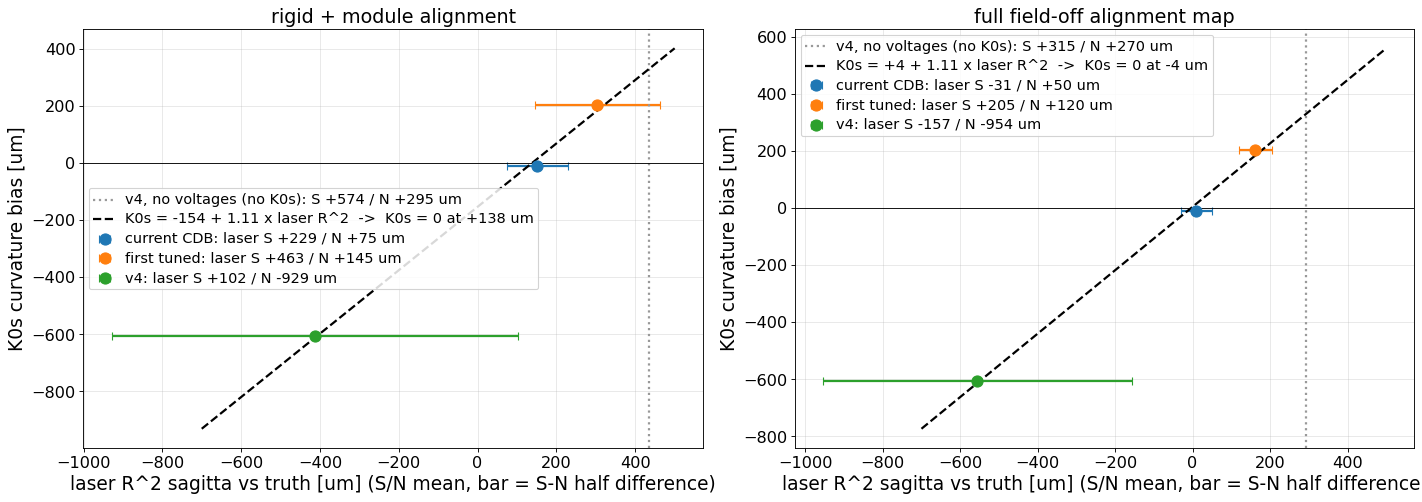

In [4]:
show(aq.fig_k0s_calibration())

With the full alignment: **K0s = +4 + 1.11 × laser R²** (residuals ≤ 25 µm, slope ≈ 1 as it must be): **K0s balance
0 ↔ laser R² ≈ 0** – a correction that matches the aligned CM truth gives balanced K0s. With only the rigid alignment
the zero was at +138 µm; with a PHGarfield-corrected field off as reference it is at +141 µm: the field-off R shape left
in the truth is why "better to the CM" made the tracks worse. (A 17 % N⁻/N⁺ at 2 GeV,
first tuned vs CDB, is ≈ 210 µm of sagitta: the falling spectrum amplifies it.)

### 1c. How good is the CDB, and is it kinky?

In [5]:
for s in (0, 1):
    d = cb.describe(cb.resid('cdb', s))
    print(f"CDB {c.SIDES[s]:5s}: R^2 {d['R2']:+5.0f} um, beyond-quad {d['beyond_quad']*1000:4.0f} um, steps at 40.5 / 57.5 cm {d['step1']:+.2f} / {d['step2']:+.2f} mm, pointing {d['pointing']:+.2f} mm")

CDB South: R^2   -31 um, beyond-quad  195 um, steps at 40.5 / 57.5 cm -0.17 / +0.28 mm, pointing +0.41 mm
CDB North: R^2   +50 um, beyond-quad  106 um, steps at 40.5 / 57.5 cm -0.31 / -0.13 mm, pointing +1.71 mm


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/calib.py:29: RuntimeWarning: Mean of empty slice
  _cache[k] = np.nanmean([aq.wprof(aq.full_aligned(r, ta.v4_tag(b, tag), s)) for r, b in aq.blocks(runs)], axis=0)


The CDB is on target within ±50 µm (South −31, North +50 µm; target 0) and **not kinky**: module-boundary steps
≤ 0.31 mm, beyond-quadratic 0.11–0.20 mm.

## 2. Space charge (v5 scan: static centre, 11 maps × b 0.50 … 0.80, 17 beam blocks)
**Method.** Per CM stripe, the corrected RΔφ is fitted linearly vs the block GEM current over a set of blocks: static,
alignment and truth cancel; with the static-only correction the slope is the data response per µA, with a map it is what
the map misses. The space-charge **shape** must be the same everywhere, so one map and one b are fitted jointly over the
clean difference sets (weights ∝ σ(I)², the lever arm):
- **South**: within 795xx (σ_I 0.29 µA), within 80892 + 81558 (0.43), 79516 vs 80892 / 81558 (1.99 µA);
- **North**: within 795xx only – the North static moves between runs (apparent response across periods −160 …
  −2700 µm/µA vs +864 within 795xx), even between 80892 and 81558.

What is shown: per map, the joint residual rms beyond linear (what a TPC-only track keeps) and the joint residual R² vs b;
right: the residual of the best map per set vs R.

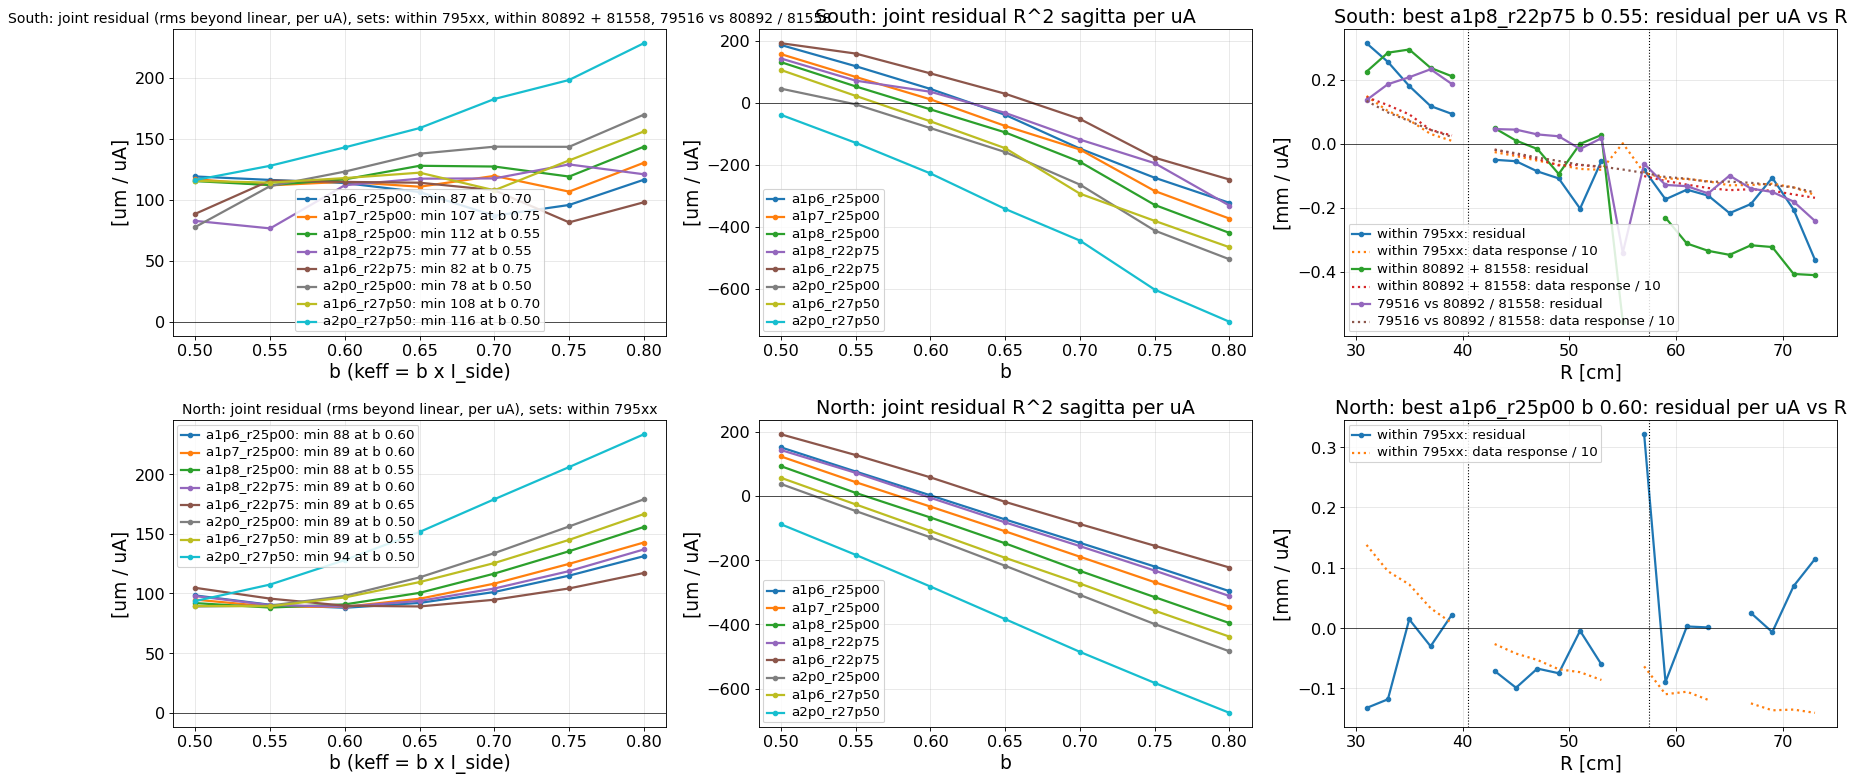

In [6]:
show(v.fig_joint())

In [7]:
for s in (0, 1):
    J = v.joint(s)
    R = sorted(((r['score'].min(), m, r['b'][np.argmin(r['score'])], float(np.interp(0, r['r2'][np.argsort(r['r2'])], r['b'][np.argsort(r['r2'])]))) for m, r in J.items()))
    print(c.SIDES[s], ':')
    for sc, m, b, bz in R:
        print(f"   {m:20s} joint rms {sc*1000:5.1f} um/uA, min at b {b:.2f}; joint R^2 = 0 at b {bz:.3f}")

South :
   a1p8_r22p75_w2_o0    joint rms  76.6 um/uA, min at b 0.55; joint R^2 = 0 at b 0.626
   a2p0_r22p75_w2_o0    joint rms  77.5 um/uA, min at b 0.55; joint R^2 = 0 at b 0.566
   a2p0_r25p00_w2_o0    joint rms  77.8 um/uA, min at b 0.50; joint R^2 = 0 at b 0.544
   a1p6_r22p75_w2_o0    joint rms  81.6 um/uA, min at b 0.75; joint R^2 = 0 at b 0.667
   a1p7m_r22p75_w2_o0   joint rms  85.3 um/uA, min at b 0.50; joint R^2 = 0 at b 0.648
   a1p6_r25p00_w2_o0    joint rms  87.0 um/uA, min at b 0.70; joint R^2 = 0 at b 0.626
   a1p7m_r25p00_w2_o0   joint rms 106.8 um/uA, min at b 0.75; joint R^2 = 0 at b 0.606
   a1p6_r27p50_w2_o0    joint rms 107.9 um/uA, min at b 0.70; joint R^2 = 0 at b 0.563
   a1p8_r27p50_w2_o0    joint rms 111.6 um/uA, min at b 0.50; joint R^2 = 0 at b 0.517
   a1p8_r25p00_w2_o0    joint rms 112.2 um/uA, min at b 0.55; joint R^2 = 0 at b 0.585
   a2p0_r27p50_w2_o0    joint rms 116.3 um/uA, min at b 0.50; joint R^2 = 0 at b 0.500


North :
   a1p6_r25p00_w2_o0    joint rms  88.0 um/uA, min at b 0.60; joint R^2 = 0 at b 0.601
   a1p8_r25p00_w2_o0    joint rms  88.2 um/uA, min at b 0.55; joint R^2 = 0 at b 0.556
   a1p8_r27p50_w2_o0    joint rms  88.5 um/uA, min at b 0.50; joint R^2 = 0 at b 0.500
   a2p0_r22p75_w2_o0    joint rms  88.7 um/uA, min at b 0.55; joint R^2 = 0 at b 0.564
   a1p7m_r22p75_w2_o0   joint rms  88.7 um/uA, min at b 0.60; joint R^2 = 0 at b 0.617
   a1p7m_r25p00_w2_o0   joint rms  88.8 um/uA, min at b 0.60; joint R^2 = 0 at b 0.578
   a1p8_r22p75_w2_o0    joint rms  88.9 um/uA, min at b 0.60; joint R^2 = 0 at b 0.597
   a2p0_r25p00_w2_o0    joint rms  89.1 um/uA, min at b 0.50; joint R^2 = 0 at b 0.522
   a1p6_r22p75_w2_o0    joint rms  89.1 um/uA, min at b 0.65; joint R^2 = 0 at b 0.638
   a1p6_r27p50_w2_o0    joint rms  89.4 um/uA, min at b 0.55; joint R^2 = 0 at b 0.534
   a2p0_r27p50_w2_o0    joint rms  93.7 um/uA, min at b 0.50; joint R^2 = 0 at b 0.500


**Reading.**
- **Inner kink**: 22.75–25 cm; 27.5 cm is always the worst (South and North).
- **South**: α 1.8–2.0 at r0 22.75 / 25 are best jointly (77–78 µm/µA), but the cross-period set alone prefers
  α 1.6–1.7 at r0 25 (36 µm/µA) and several minima sit at the edge of the b scan → the South shape is constrained only
  weakly; b ≈ 0.55–0.63.
- **North**: all maps within 1 µm/µA on 795xx (α 1.6 r0 25, b 0.60 marginally best).
- b from within 795xx (0.66–0.68 South) is higher than across the periods (0.55–0.57): a mild non-linearity of the
  South response with the current.

## 3. Static (v5 grid at 795xx: IFC ±60 V × OFC ±80 V × frames ±60 around the iteration-2 centre)
**What the static has to do.** With the space charge fixed (Section 2), what is left at 795xx vs the aligned truth is the
static model. A TPC-only track keeps of RΔφ(R) only (i) the **R² curvature** (sagitta → momentum, the K0s balance) and
(ii) everything **beyond a smooth curve** (resolution). Offset and slope are a shift and a rotation of the whole track.

**The quantities plotted:**
- **R² sagitta** [µm]: the quadratic term of RΔφ(R) over 30–76 cm, expressed as the sagitta of a 46 cm chord.
  Target 0 (= K0s balance 0, Section 1b).
- **Step at a module boundary** [mm] (40.5 cm = R1/R2, 57.5 cm = R2/R3): the jump of RΔφ across the boundary – a
  straight line is fitted to the last 3 points (2 cm bins) before and the first 3 after the boundary, both are
  extrapolated to the boundary, step = after − before. A step is a kink a track cannot follow: it shows up as a
  residual at the module edges and, if not symmetric, as a fake curvature. The module frames (charged frame bars at
  the GEM plane) make such steps; their charge in PHGarfield is the knob.
- **Beyond-quadratic rms** [µm]: what is left after removing a quadratic in R (wiggles, steps).

**The three knobs** (vs the automatic field-cage values): IFC voltage (E_r at small R: curvature), OFC voltage (E_r at
large R: curvature of the opposite sign), frame charge (steps at the module boundaries, little curvature). In the grid
each side is analysed alone (the two drift volumes are independent).

### 3b. The static grid: R² and module steps vs IFC, OFC, frame charge

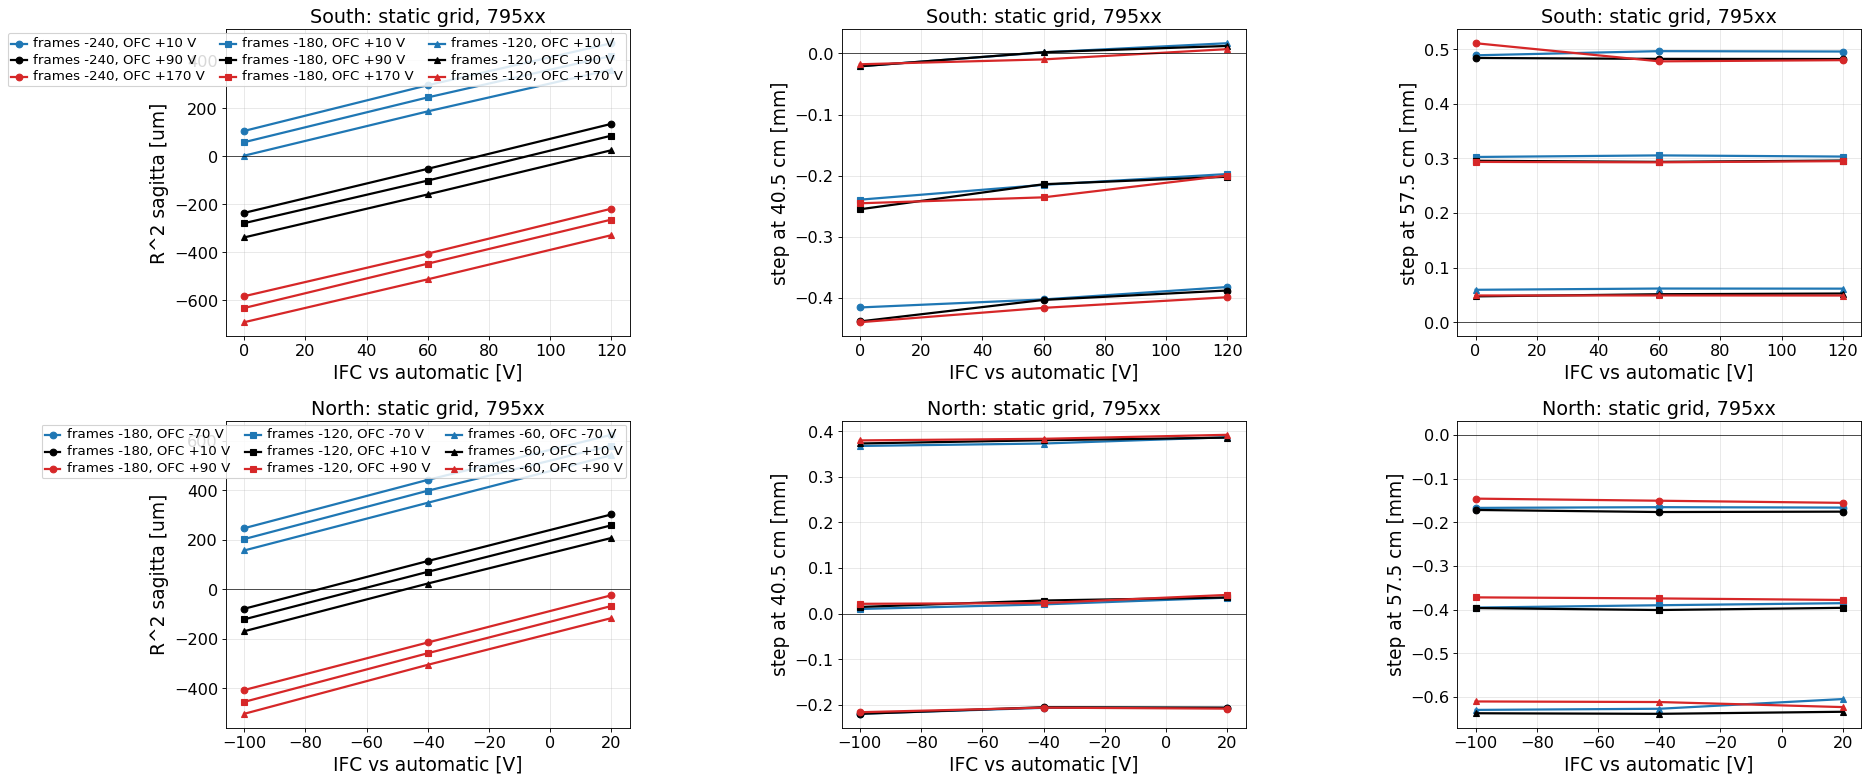

In [8]:
show(v.fig_static_grid())

In [9]:
for s in (0, 1):
    for fr in (None, -180, -120):
        o = v.static_solution(s, fr)
        print(f"{c.SIDES[s]:5s} frames {o['frames']:+6.0f}{' (min steps)' if fr is None else ''}: R^2 = 0 needs IFC {o['IFC']:+5.0f} V, OFC {o['OFC']:+5.0f} V (vs automatic); "
              f"steps {o['step1']:+.2f} / {o['step2']:+.2f} mm, beyond-quad {o['beyond_quad']*1000:.0f} um  (R^2 with no field-cage change {o['R2_noV']:+.0f} um)")

South frames   -107 (min steps): R^2 = 0 needs IFC    -4 V, OFC    +6 V (vs automatic); steps +0.02 / +0.02 mm, beyond-quad 180 um  (R^2 with no field-cage change +36 um)
South frames   -180: R^2 = 0 needs IFC   -11 V, OFC   +16 V (vs automatic); steps -0.23 / +0.29 mm, beyond-quad 190 um  (R^2 with no field-cage change +102 um)
South frames   -120: R^2 = 0 needs IFC    -5 V, OFC    +7 V (vs automatic); steps -0.02 / +0.07 mm, beyond-quad 181 um  (R^2 with no field-cage change +48 um)
North frames   -167 (min steps): R^2 = 0 needs IFC   -32 V, OFC   +41 V (vs automatic); steps -0.17 / -0.21 mm, beyond-quad 110 um  (R^2 with no field-cage change +270 um)
North frames   -180: R^2 = 0 needs IFC   -33 V, OFC   +43 V (vs automatic); steps -0.23 / -0.16 mm, beyond-quad 101 um  (R^2 with no field-cage change +280 um)
North frames   -120: R^2 = 0 needs IFC   -28 V, OFC   +36 V (vs automatic); steps +0.07 / -0.39 mm, beyond-quad 141 um  (R^2 with no field-cage change +234 um)


**Reading.**
- The grid is linear (fit rms ≤ 5 µm in R²): IFC +300 µm, OFC −420 µm of R² per +100 V; frames +60 → −50 µm R² and
  steps +0.2 … +0.3 / −0.2 mm.
- **South**: frames ≈ −110 … −120 flatten both module steps (+0.02 / +0.02 mm); R² is then already +36 … +48 µm
  with **no** field-cage change, and R² = 0 needs only IFC ≈ −5 V, OFC ≈ +7 V: **South static ≈ automatic field cage +
  frames −110**.
- **North**: no frame charge flattens both boundaries (40.5 cm wants ≈ −120, 57.5 cm ≈ −180): ≈ 0.2 mm left – the
  frame model itself (CDB maps: only φ harmonics m ≤ 24, radial ringing; North 40.5 cm too strong). With frames ≈ −170,
  R² = 0 needs IFC ≈ −30 V, OFC ≈ +40 V (R² +270 µm without them).
- These numbers assume α 1.8 r0 22.75 at b 0.70 / 0.60; with another map / b the R² shifts (−135 µm per +0.1 keff).
- Reading the plots: R² is linear in IFC and OFC and shifts with the frames; the steps depend (almost) only on the
  frames – the horizontal lines – which is why the frames are fixed first by the steps and the voltages then by R².

## 4. Next
1. **Frames**: m 120 maps (both sides) are sharp in φ (E_φ beyond 2 cm from a frame 16 % vs 60 % in the CDB maps);
   smooth the remaining radial ringing offline (steepness = smoothing width) and fit steepness and strength per side to
   the CM residuals at the module boundaries (offline drift integral, calibrated on the 75073 frame scan).
2. **Space charge**: extend b below 0.50 and refine near the minima; more blocks per run (3000 / 4000) for the South
   cross-period lever arm.
3. **Static per period** for North (795xx and 80892 / 81558 separately).
4. One combined condor scan, then one K0s check (target: laser R² 0 ↔ K0s balance 0).

## 5. Summary
1. **Alignment** (Section 1): rigid + 72 module offsets + common fine R profile from raw field off; with it
   K0s = +4 + 1.11 × laser R²: matching the aligned CM truth = balanced K0s.
2. **We are at the CDB level at 795xx and much better at high luminosity**, with keff linear in the GEM current.
3. **Space charge**: inner kink 22.75–25 cm; α 1.6–2.0 (South weakly constrained), b ≈ 0.55–0.63 South, 0.60 North;
   North static changes between runs (only within-period differences are clean).
4. **Static**: South = automatic field cage + frames ≈ −110 (IFC −5, OFC +7 V); North frames ≈ −170, IFC ≈ −30,
   OFC ≈ +40 V, limited by the frame model → better frame maps next.

## 6. Final: new vs current CDB against the aligned truth (795xx)
**New** = the v5 static-grid point closest to the solution of Section 3 for each side (small R², flat steps, small
voltages) with α 1.8 at the ΔI b: South IFC 0, OFC +10 V, frames −120; North IFC +20, OFC +90 V, frames −180.
Fully aligned truth (rigid + modules + fine R profile from field off), sector edges excluded.

### 6a. Overall, φ-averaged (K0s-weighted), offset + slope removed (what a track keeps); also 80892 / 81558 with the
v5 static centre and the best map

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v5ana.py:156: RuntimeWarning: Mean of empty slice
  return np.nanmean(P, axis=0)


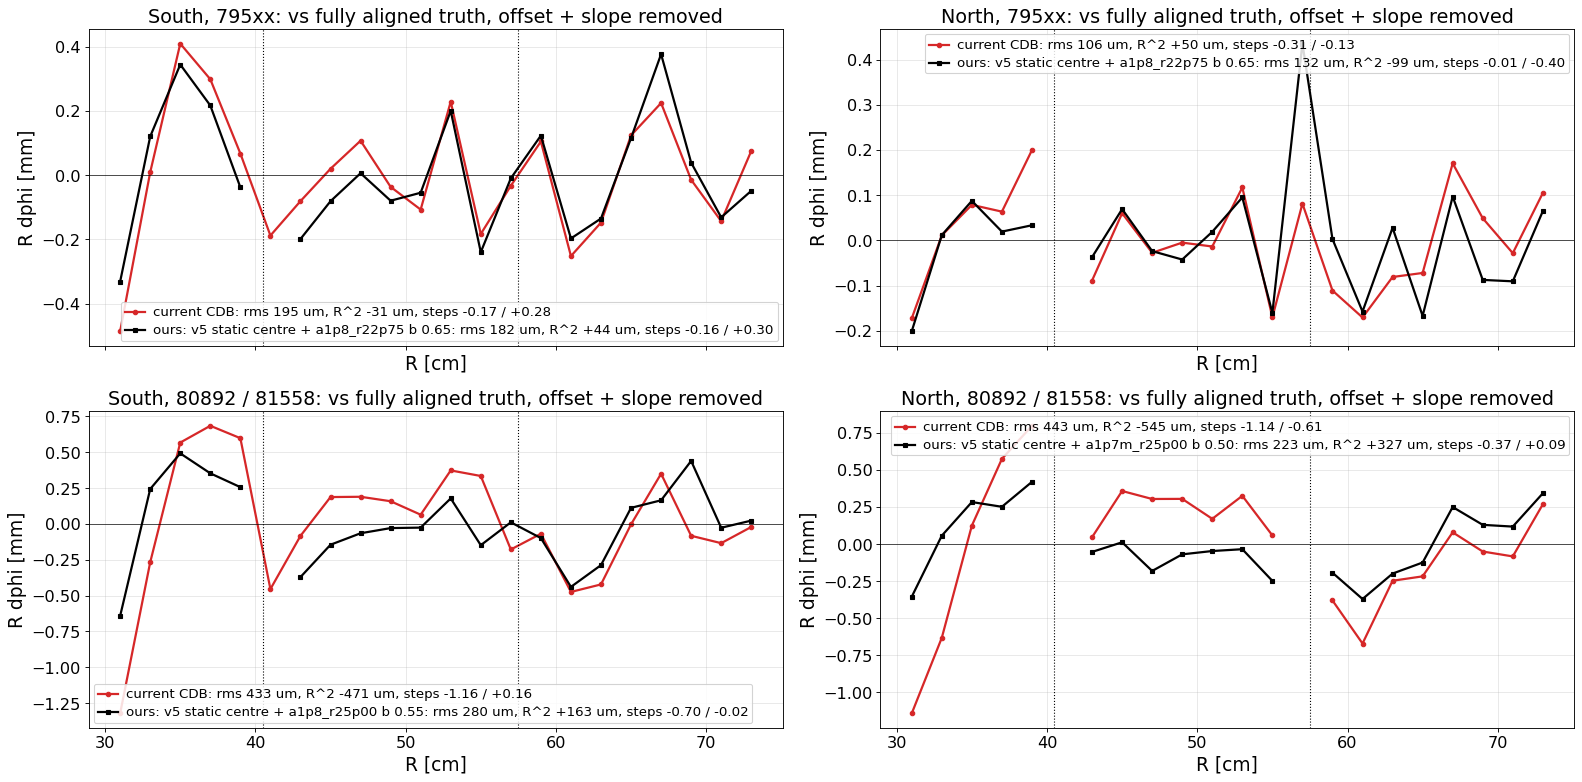

In [10]:
show(v.fig_vs_cdb())

- 795xx: new and CDB at the same level (≈ 0.1–0.2 mm beyond linear); at high luminosity the new correction is much
  better (the CDB keff offset leaves ≈ −0.5 mm of R²).

### 6b. Per 30° sector: R² sagitta and pointing at R = 0 vs φ

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v5ana.py:250: RuntimeWarning: Mean of empty slice
  D = np.nanmean(D, axis=0)


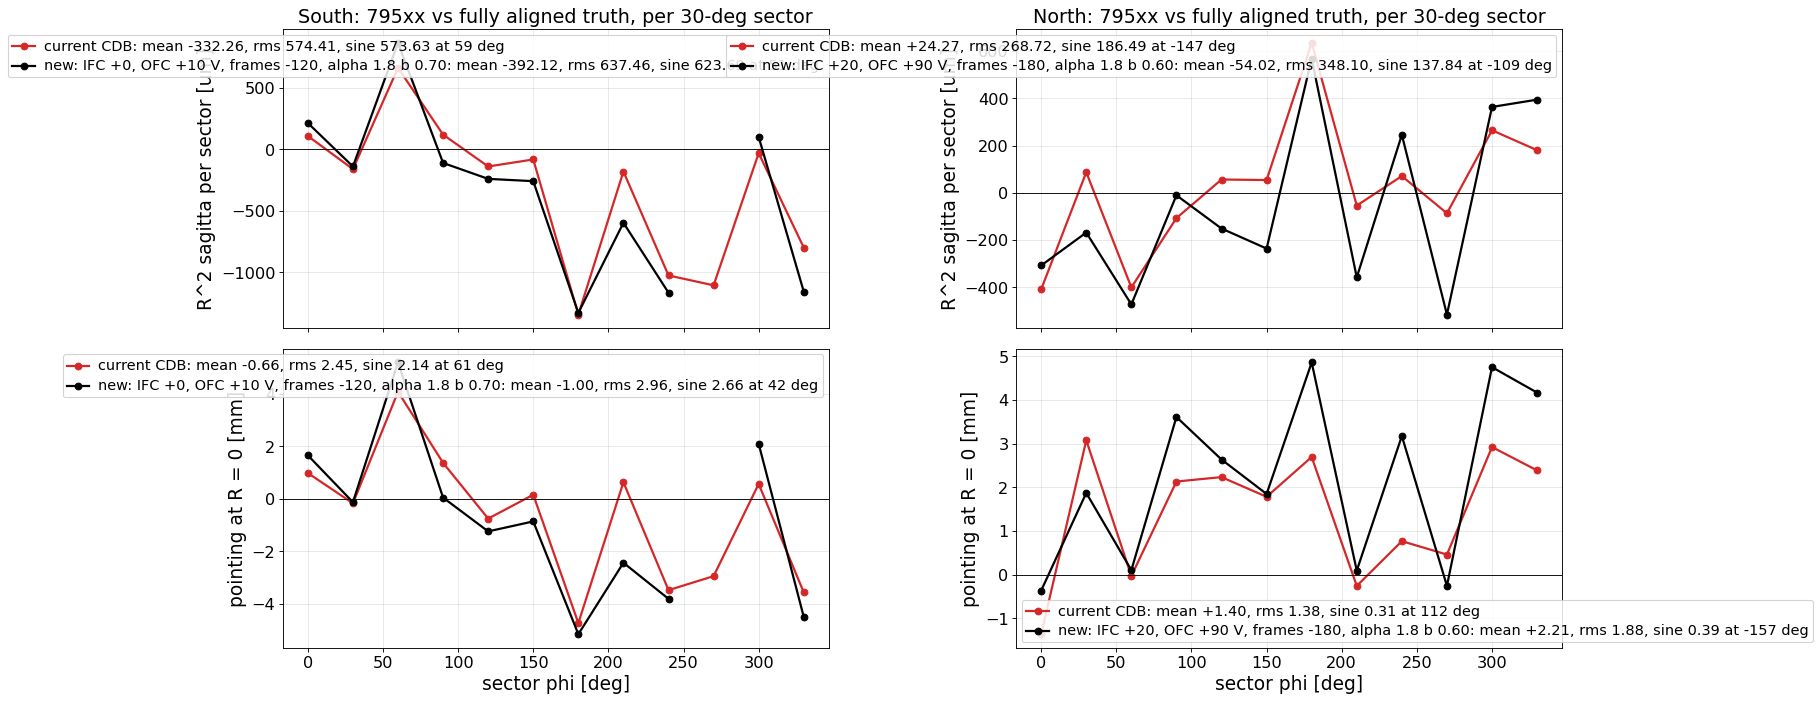

In [11]:
show(v.fig_final_sectors())

Per sector the quadratic is fitted to ~100–170 clusters, so single sectors scatter by a few hundred µm; the first
harmonic (sine) is what to compare. New and CDB have the same φ pattern – it is in the alignment / static, not in the
space charge.

### 6c. RΔφ vs R in four φ bins (offset kept)

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v5ana.py:269: RuntimeWarning: Mean of empty slice
  P = np.nanmean(P, axis=0); d = cb.describe(P)


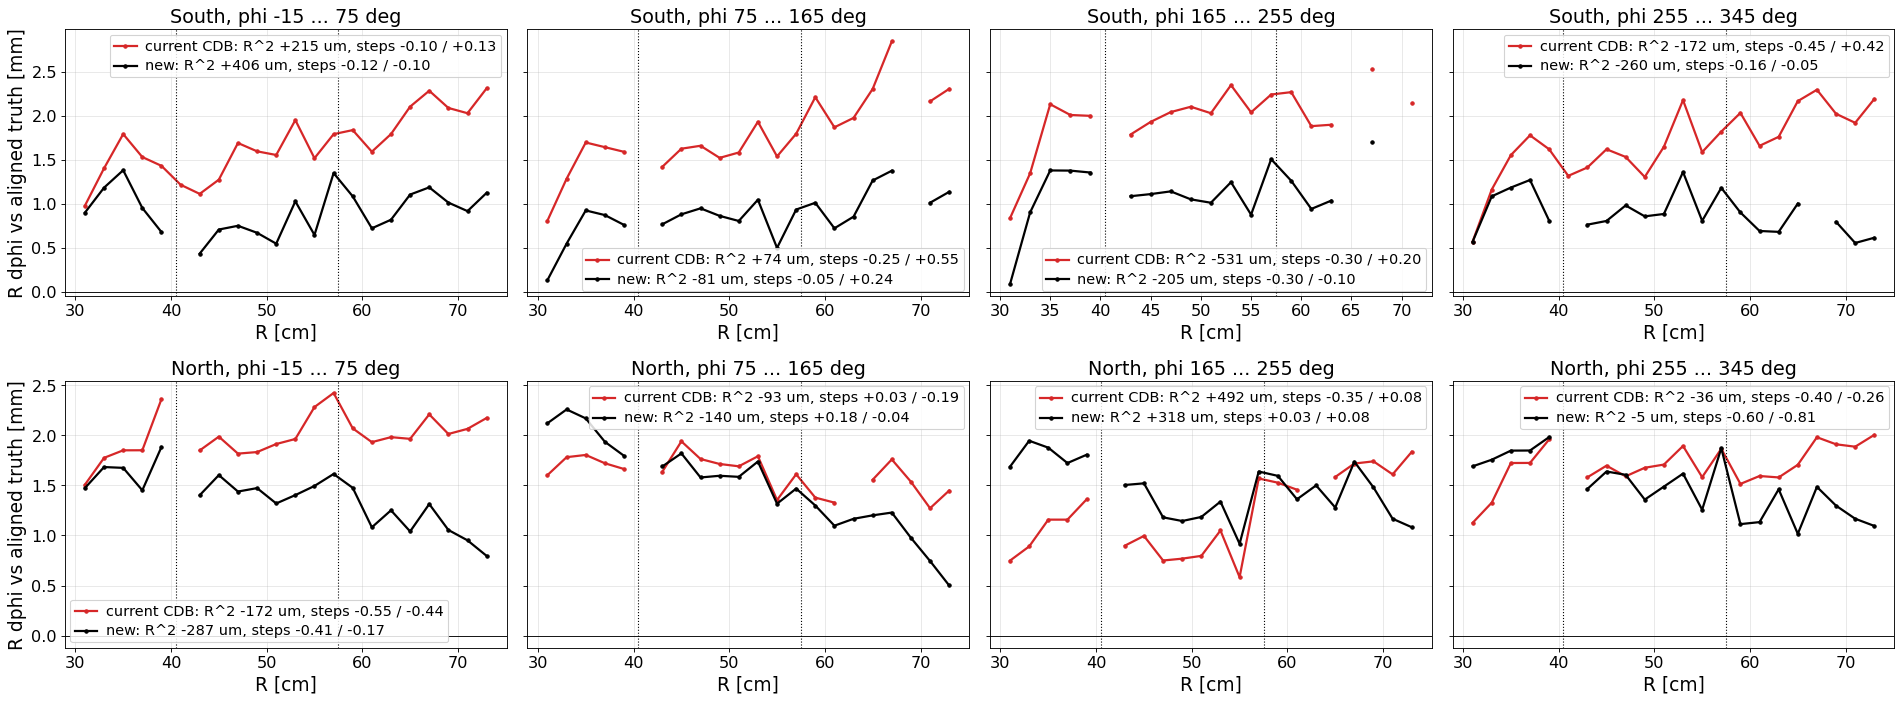

In [12]:
show(v.fig_final_rdphi())

The new correction removes ≈ 0.8 mm of the flat offset of the CDB (a rotation / shift the tracks absorb) and keeps the
R shape; the module steps are smaller in South.

### 6d. dR vs R in four φ bins (balanced two-row clusters only)

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v5ana.py:294: RuntimeWarning: Mean of empty slice
  P = np.nanmean(P, axis=0) if P else np.full(len(ta.S3_RC), np.nan)


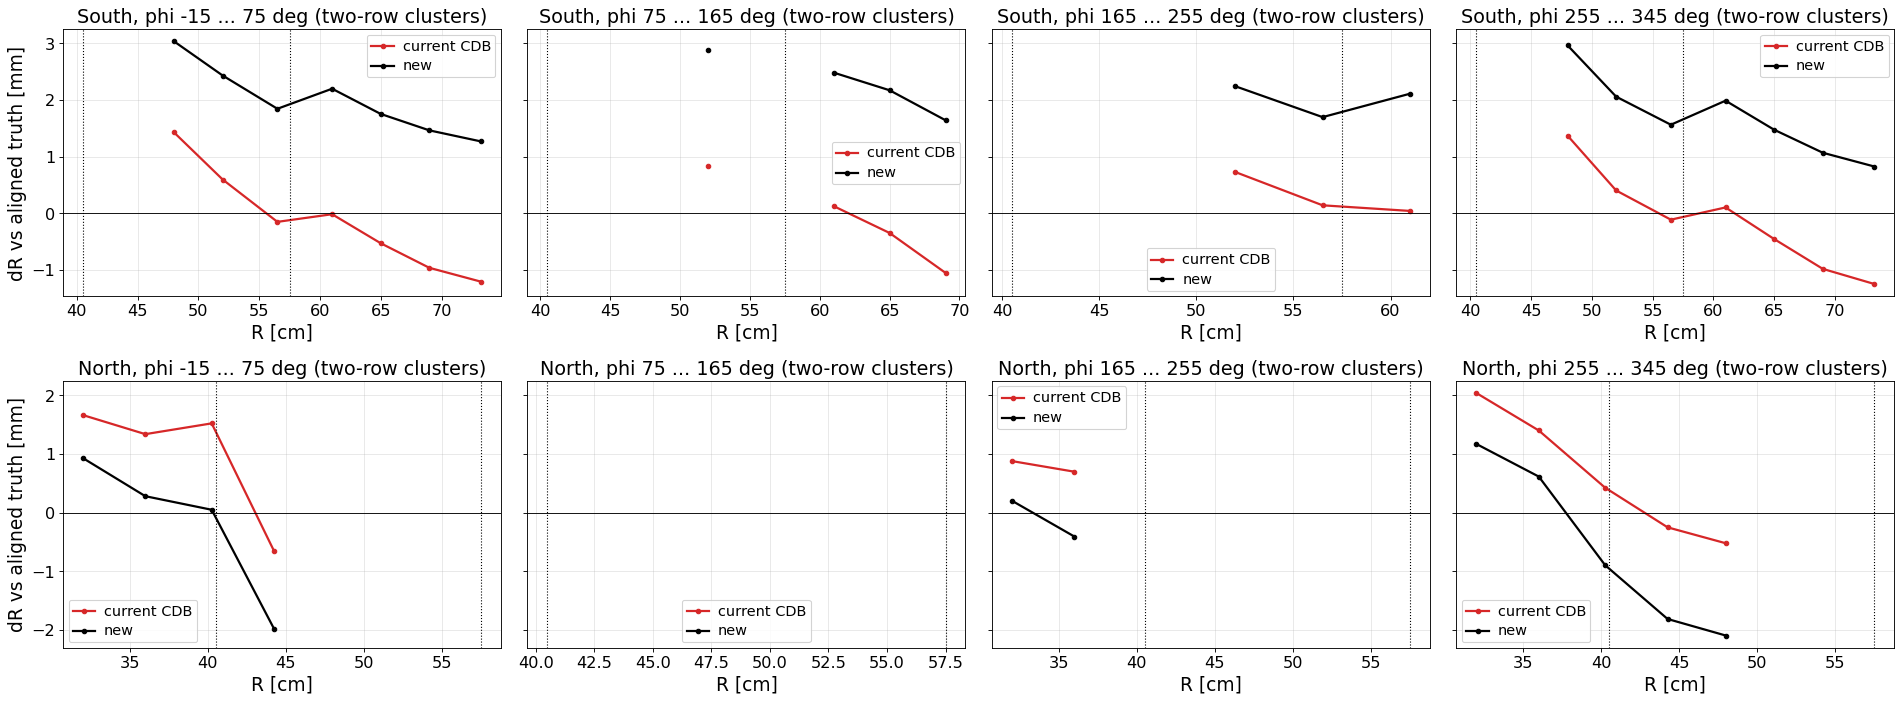

In [13]:
show(v.fig_final_dr())

Only clusters split between two pad rows give a radial measurement (one-row CM clusters saturate at ± half a pad
pitch); North R2 / R3 has almost none. Where measured, the new correction moves dR by +1 … +2 mm in South (the field
cage / frame difference) – dR does not enter the track curvature directly but tests the radial part of the static.